In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import find_peaks, peak_widths, savgol_filter
import pandas as pd
import h5py
from typing import Literal
import struct

plt.rcParams["figure.dpi"] = 256

In [2]:
def plot_with_peaks(
    data,
    n_bins,
    prominence=None,
    xlabel="",
    title="",
    xlims=None,
    savgol_window=None,
    savgol_strength=1.0,
    clip_counts=None,
    stacked=False,
    legend=None,
    bin_range=None,
    text_size=5,
):
    if not stacked:
        signals = [data]
    else:
        signals = data

    bottom = np.zeros(n_bins)

    for signal in signals:
        counts, bins = np.histogram(signal, bins=n_bins, density=False, range=bin_range)
        if savgol_window is not None:
            background = savgol_filter(counts, window_length=savgol_window, polyorder=3)
            counts = counts - background * savgol_strength

        if clip_counts is not None:
            counts[counts > clip_counts] = clip_counts

        bin_width = np.diff(bins).mean()
        bin_centers = (bins[:-1] + bins[1:]) / 2.0
        height_scale = counts.max()

        plt.bar(bin_centers, counts, width=bin_width, align="center", bottom=bottom)
        plt.xlim(xlims)
        bottom += counts
        bottom = np.round(bottom, 10)
        if prominence is not None:
            peaks, props = find_peaks(counts, prominence=prominence)
            half_widths = peak_widths(counts, peaks)[0] * bin_width
            for x, y, half_width in zip(bin_centers[peaks], counts[peaks], half_widths):
                plt.errorbar(
                    [x],
                    [y],
                    xerr=[half_width],
                    c="black",
                    fmt="",
                    capsize=2,
                    elinewidth=0.2,
                    capthick=0.2,
                )
                plt.annotate(
                    f"{x:.03f} ± {half_width:.03f} MeV",
                    (x, y + height_scale * (0.005 * text_size)),
                    ha="left",
                    fontsize=text_size,
                )

    plt.xlabel(xlabel)
    plt.ylabel("Count")
    # plt.ylim(ylims)
    plt.title(title)
    if legend is not None:
        plt.legend(legend)

    # plt.figure()
    plt.show()

# Loaders

In [3]:
keys = [
    "E",
    "name",
    "z",
    "rho",
    "phi",
    "momentumZ",
    "momentumRho",
    "momentumPhi",
    "sourceDepth",
    "sourceRadius",
    "sourceE",
    "sourcePDG"
]

def decode(b):
    return b.decode("utf-8")


decode_v = np.vectorize(decode)


def load_hdf5(path):
    dfs = []
    with h5py.File(path, "r") as f:
        for key in keys:
            data = f["default_ntuples"]["Measurement"][key]["pages"][()]
            if isinstance(data[0], bytes):
                data = decode_v(data)

            dfs.append(pd.DataFrame(data, columns=[key]))

    return pd.concat(dfs, axis=1)


def load_csv(path):
    df = pd.read_csv(path, comment="#", header=None)
    df.columns = keys.copy()
    print(f"{df.shape[0]:,} interactions recorded")
    return df


def load_raw(path):
    rows = []
    with open(path, "rb") as file:
        while data := file.read(3 * 8):
            energy, p_z, depth = struct.unpack("ddd", data)
            rows.append([energy, p_z, depth])
    df = pd.DataFrame(rows, columns=["E", "p_z", "z"])
    return df

In [4]:
# V4 loader. V4 has no pre-detector transport stage: production is folded straight into the detector
# with importance sampling, so there are no per-particle records at the detector surface. The nearest
# equivalent is the analog runs (CRY showers 1 m above Chromosol, soil and detector all in one
# Geant4 run), which record every particle crossing a virtual 60 x 60 cm tag plane 45 cm above the
# ground (just above the detector). load_v4_tags() gives them load_csv's column names:
#   E (MeV), name (Geant4 particle name), t (ns since the shower started; NaN if overflowed)
# Not in the V4 bundle: positions and directions (z, rho, phi, momentum*), and the source
# depth/radius per particle. The depth of origin of detected line counts is in `tdepth` (see below).

import sys
from pathlib import Path

PROJECT = Path.cwd().resolve().parents[2]  # .../ASC - Carbon Spec (run from ground-carbon/analysis)
sys.path.insert(0, str(Path.cwd() / "v4"))
sys.path.insert(0, str(PROJECT / "Final Data" / "v4_final"))
import v4lib as L  # V4 campaign helpers: capture correction, heavy-hit cleaning, NORM model, soil parameters
from spectra import CLASSES

# v4lib's built-in paths assume a different folder layout; point them at the data
L.RESULTS = PROJECT / "Final Data" / "v4_results_20261011" / "v4_results"
L.REDUCED = L.RESULTS / "reduced"
L.SOILS = PROJECT / "Geochemical Survey" / "Soil_Types_JSON_v2"
DAY = 86400.0


PDG_NAMES = {22: "gamma", 11: "e-", -11: "e+", 2112: "neutron", 2212: "proton", -2212: "anti_proton",
             12: "nu_e", -12: "anti_nu_e", 14: "nu_mu", -14: "anti_nu_mu", 13: "mu-", -13: "mu+",
             211: "pi+", -211: "pi-", 321: "kaon+", -321: "kaon-"}


def load_v4_tags(aid):
    a = L.analog(aid)
    t = a["tags"]
    out = pd.DataFrame({"E": t["E_MeV"].astype(float),
                        "name": [PDG_NAMES.get(p, "ion" if p > 1000000000 else str(p)) for p in t["pdg"]],
                        "t": a["t_trel"]})
    print(f"{out.shape[0]:,} particles crossed the tag plane in {a['exposure_s'] / 3600:.1f} h of sky ({aid})")
    return out

In [5]:
# df = load_csv("finals/big.csv")
RUN = "chromosol"            # V4 central Chromosol (for tdepth)
df = load_v4_tags("analog_box5")
df

7,166,335 particles crossed the tag plane in 12.0 h of sky (analog_box5)


,E,name,t
0,12.955241,gamma,2.737118
1,3.151904,gamma,1.856317
2,4.076955,gamma,2.137357
3,150.165558,e+,1.884699
4,22.608488,gamma,2.164785
...,...,...,...
7166330,3.389712,e-,181.929688
7166331,0.114739,e-,188.992188
7166332,0.023001,e-,189.593750
7166333,0.075662,gamma,187.382812


# Analysis

In [6]:
particle_names, particle_counts = np.unique(df["name"], return_counts=True)
# particle_nums = np.arange(0, len(particle_names))
# particle_dict = dict(zip(particle_names,particle_nums))

particle_counts, particle_names = zip(
    *sorted(zip(particle_counts, particle_names))[::-1]
)

names_dict = {
    "gamma": "$\\gamma$",
    "e-": "$e^{-}$",
    "e+": "$e^{+}$",
    "neutron": "neutron",
    "proton": "proton",
    "nu_e": "$\\nu_e$",
    "anti_nu_e": "Anti-$\\nu_e$",
    "nu_mu": "$\\nu_\\mu$",
    "anti_nu_mu": "Anti-$\\nu_\\mu$",
    "pi+": "$\\pi^{+}$",
    # V4: further particles crossing the tag plane
    "pi-": "$\\pi^{-}$",
    "mu-": "$\\mu^{-}$",
    "mu+": "$\\mu^{+}$",
    "anti_proton": "anti-proton",
    "ion": "ions (d, t, $\\alpha$, ...)",
}


Text(0, 0.5, 'Count')

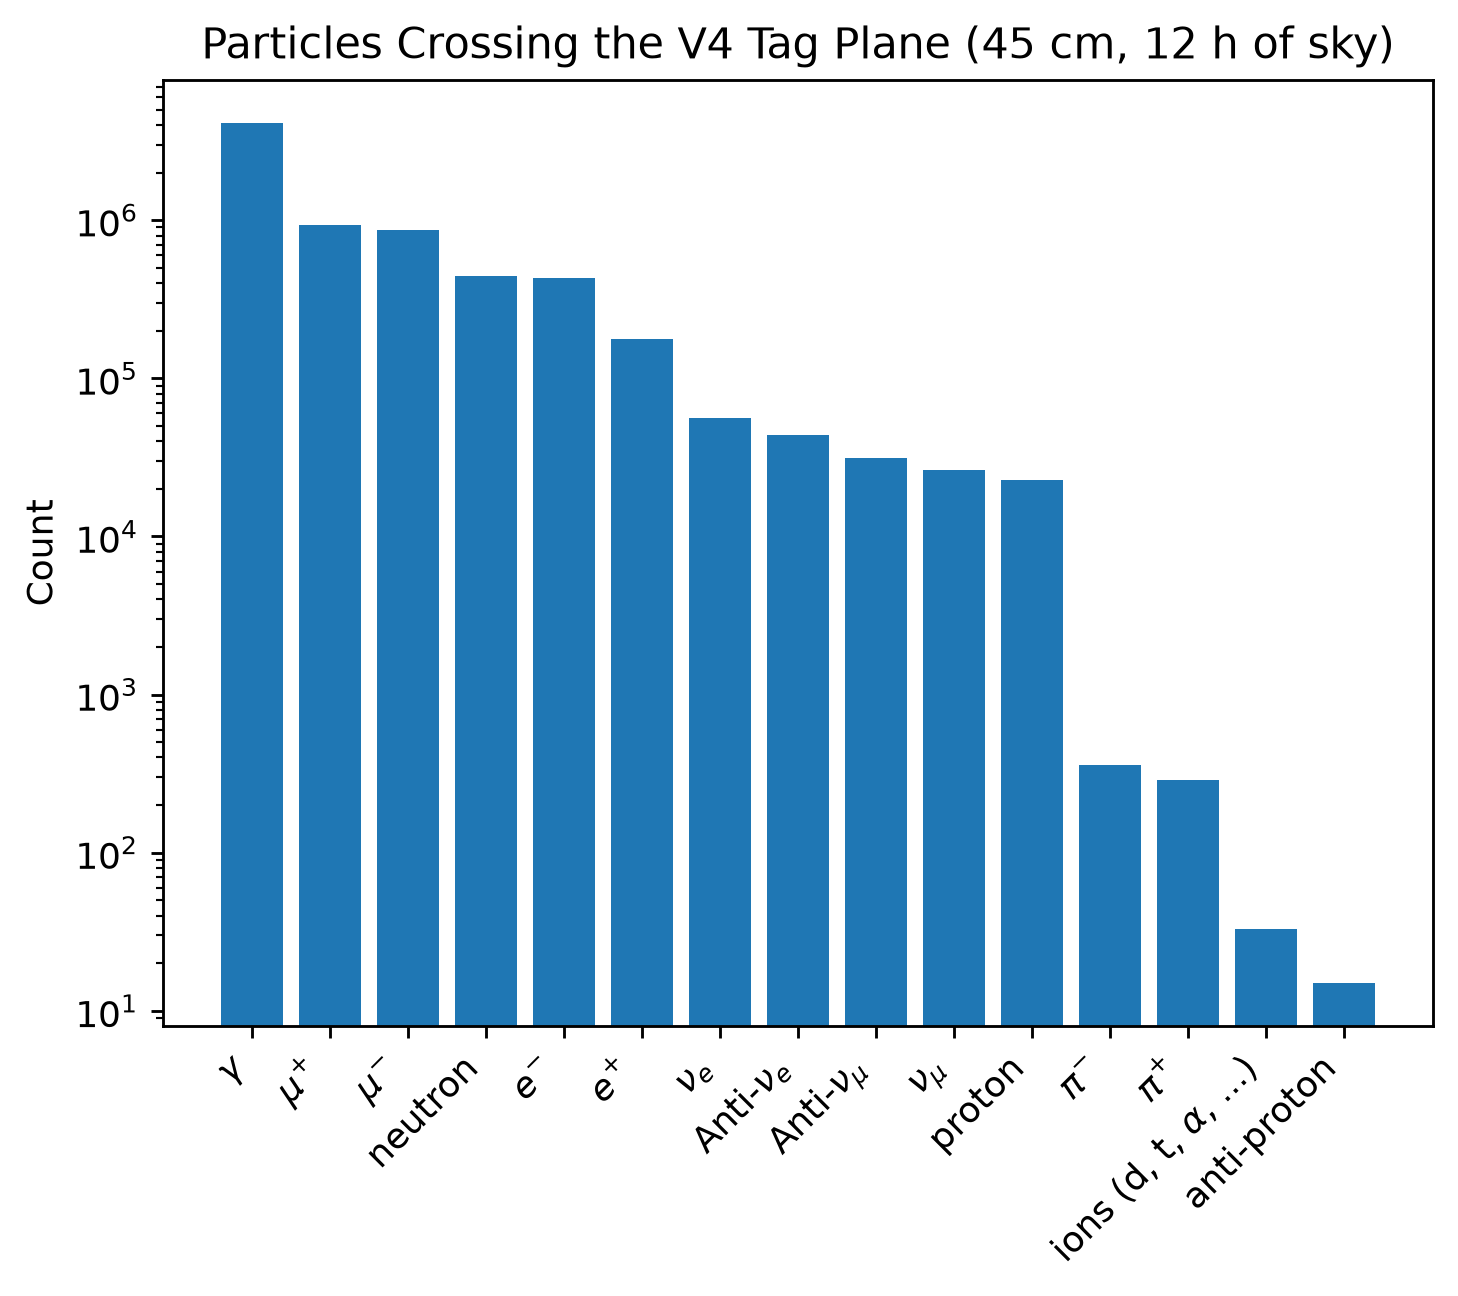

In [7]:
plt.yscale("log")

plt.bar([names_dict[name] for name in particle_names], particle_counts)
plt.xticks(rotation=45, ha='right')
plt.title("Particles Crossing the V4 Tag Plane (45 cm, 12 h of sky)")
plt.ylabel("Count")

In [8]:
gamma_prop = particle_counts[0] / np.sum(particle_counts)
gamma_prop_u = np.sqrt(particle_counts[0]) / np.sum(particle_counts)
print(f"{gamma_prop:.04f} \\pm {gamma_prop_u:.04f}")

e_prop = particle_counts[1] / np.sum(particle_counts)
e_prop_u = np.sqrt(particle_counts[1]) / np.sum(particle_counts)
print(f"{e_prop:.05f} \\pm {e_prop_u:.05f}")

0.5768 \pm 0.0003
0.12989 \pm 0.00013


## Masking Utilities

In [9]:
property_range = lambda property, lower, upper, mask=None: (
    df if mask is None else df[mask]
)[property].between(lower, upper)
energy_range = lambda lower, upper, mask=None: property_range("E", lower, upper, mask)

In [10]:
# Not available for V4: positions and directions are not recorded at the tag plane
# # plot_with_peaks(df["sourceDepth"], 100)
# # plot_with_peaks(df["sourceRadius"], 100)
# # plt.yscale("log")
# # plot_with_peaks(df["z"], 100)
# # plot_with_peaks(df["rho"], 100)
# # plot_with_peaks(df["phi"], 100)
# # plot_with_peaks(df["momentumZ"], 100)
# # plot_with_peaks(df["momentumRho"], 100)
# mask = df["z"].between(200, 368)
# diff = (df["phi"]-df["momentumPhi"]) % (2 * np.pi) - np.pi
# plot_with_peaks(diff, 2048, xlabel="Momentum Angle from Radial")
# df[mask]

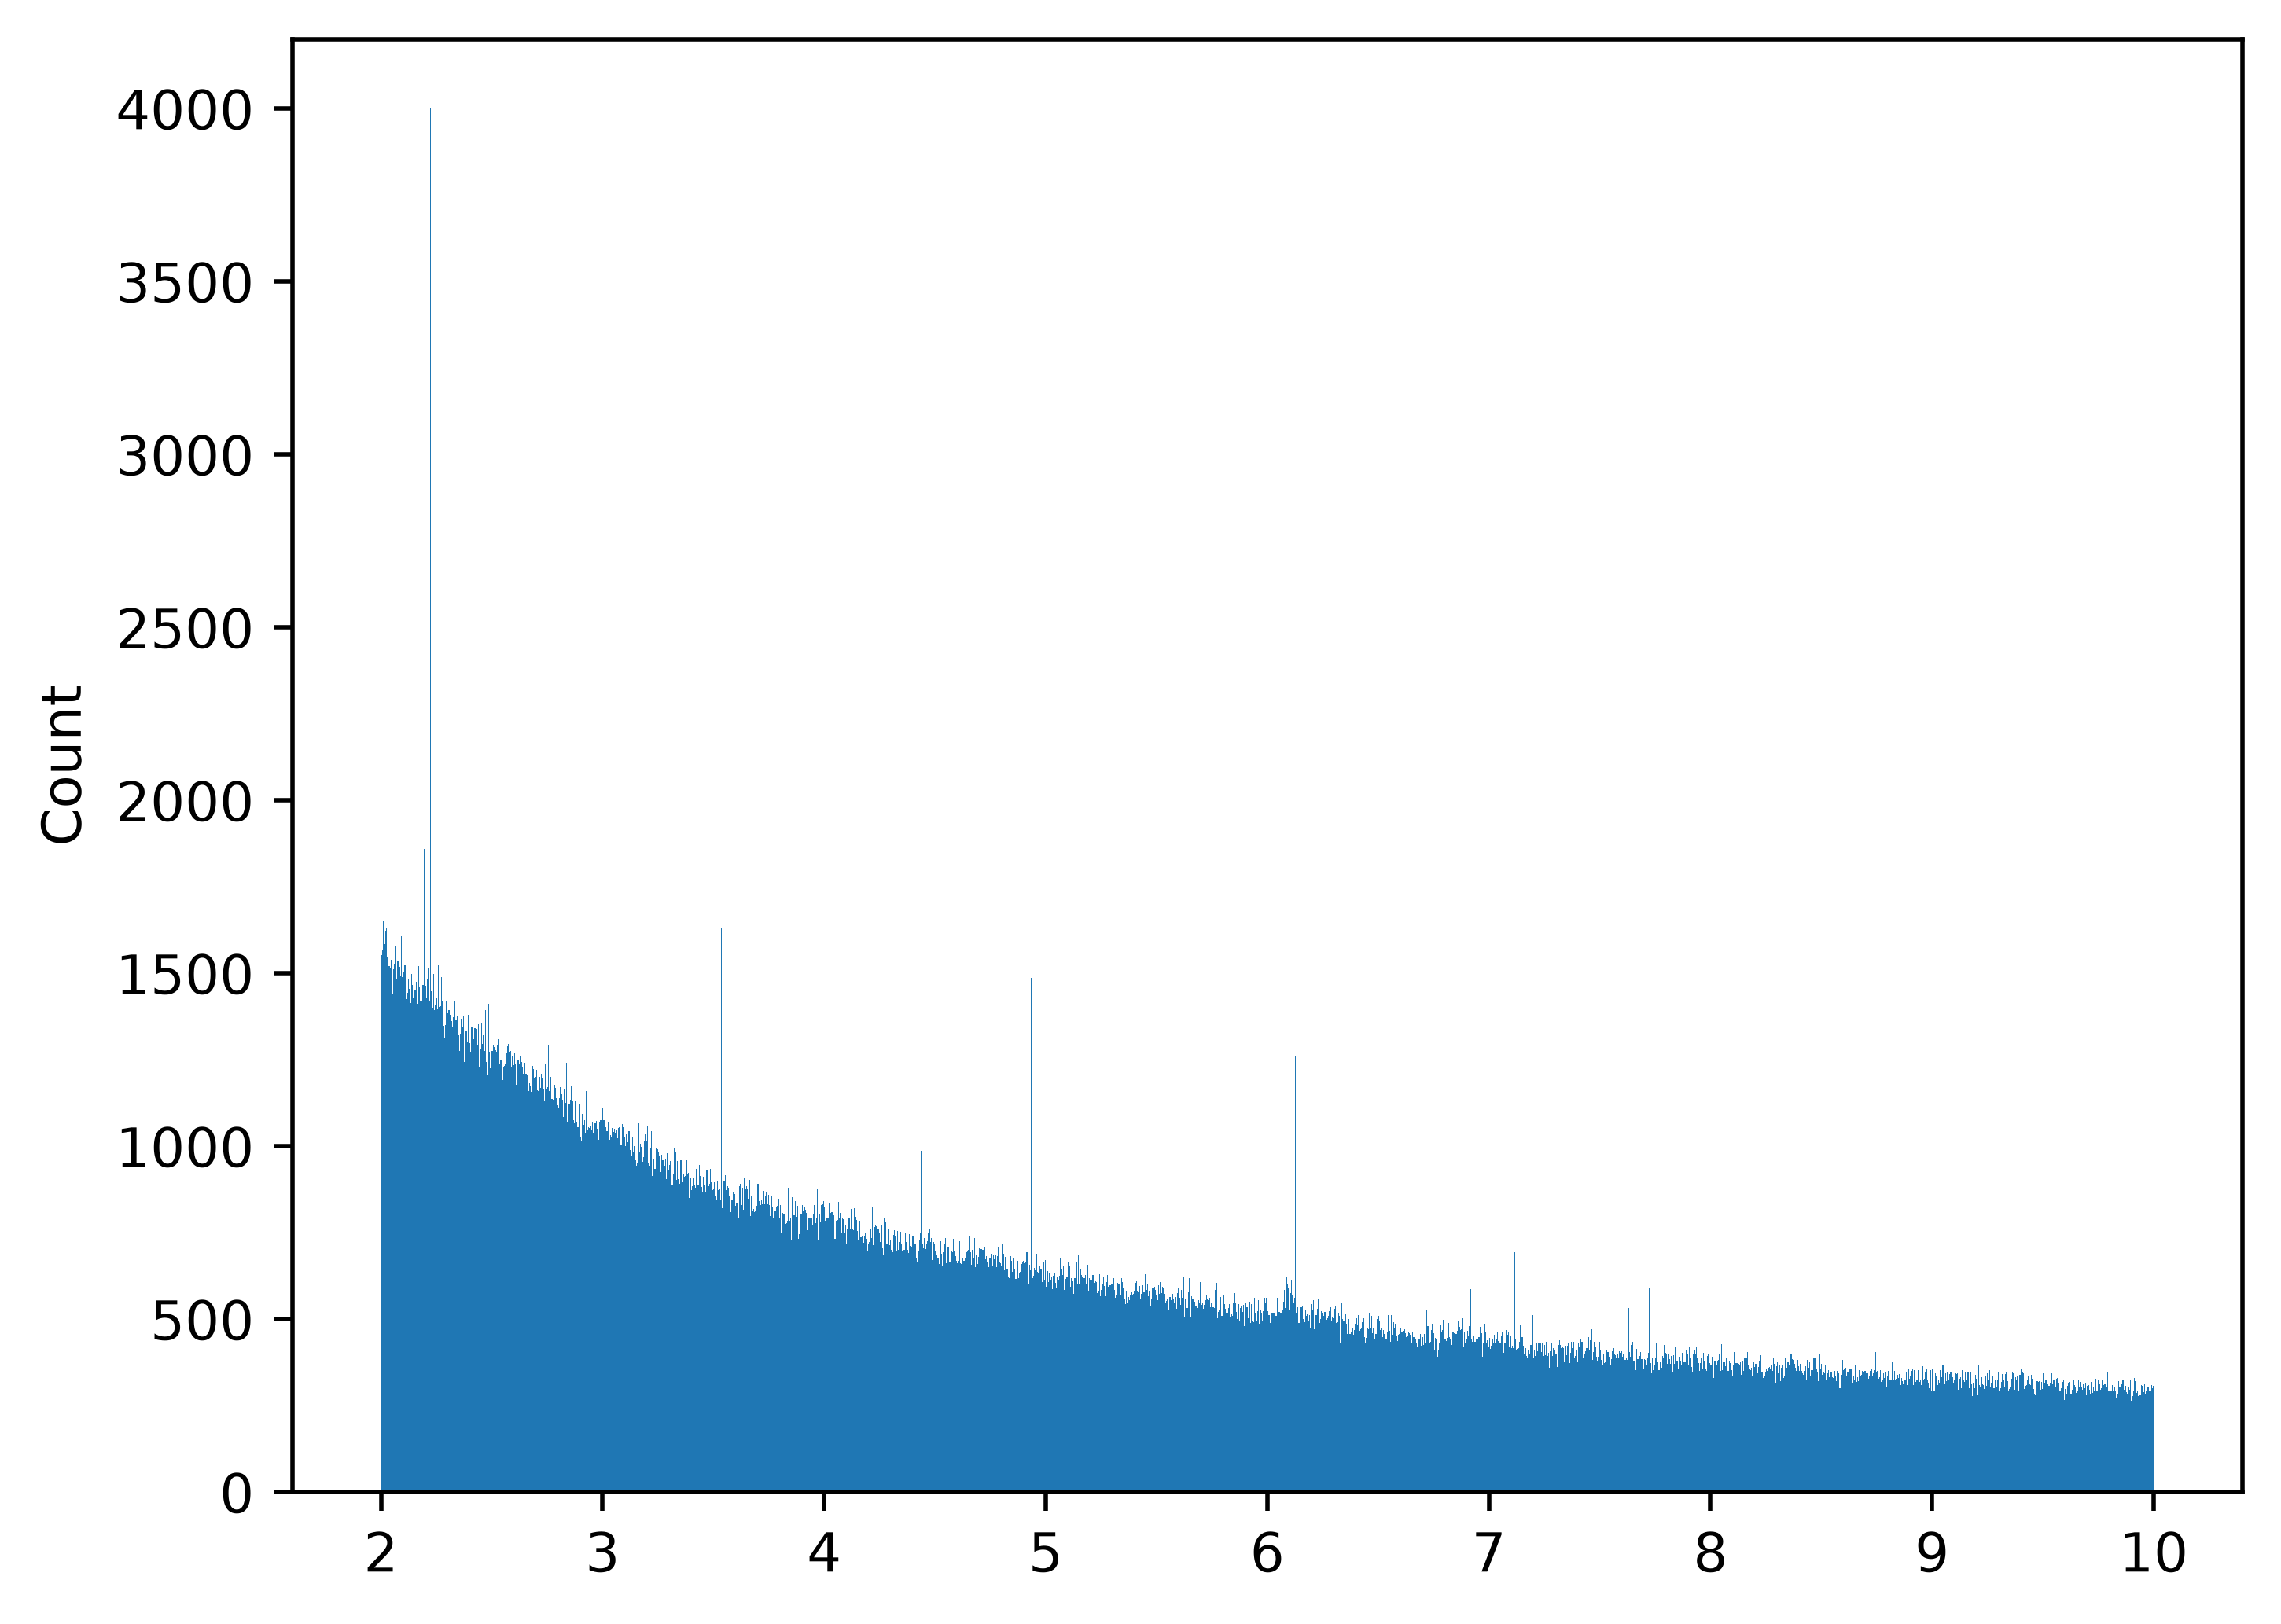

In [11]:
plt.rcParams["figure.dpi"] = 500
plot_with_peaks(df[energy_range(2.0, 10.0)]["E"], n_bins=2048, clip_counts=4000)

In [12]:
# Not available for V4: positions and source radius are not in the V4 bundle; depth of origin is in tdepth (next cells)
# plt.close()
# mask = df["z"].between(0, 360)
# plt.hexbin(
#     df[mask]["rho"] / 10 * np.cos(df[mask]["phi"]),
#     df[mask]["rho"] / 10 * np.sin(df[mask]["phi"]),
#     # C=df["E"],
#     # reduce_C_function=np.sum,
#     linewidths=0.2,
#     # vmax=0.5,
#     # norm=LogNorm(),
# )
# plt.colorbar(label="Count")
# plt.xlabel("$x$ (cm)")
# plt.ylabel("$y$ (cm)")
# plt.title("Positions of Particles Resulting in Detector Pulses")
# plt.show()
#
# plt.hexbin(
#     df[mask]["sourceRadius"] / 10,
#     df[mask]["sourceDepth"] / 10,
#     # C=df["E"],
#     # reduce_C_function=np.sum,
#     linewidths=0.2,
#     # vmax=0.5,
#     # norm=LogNorm(),
# )
# plt.colorbar(label="Count")
# plt.xlabel("Distance from $z$-axis, $\\rho$ (cm)")
# plt.ylabel("$z$ (cm)")
# plt.title("Positions of Particles Resulting in Detector Pulses")
# plt.show()

In [13]:
# num_in_vol = df[(df["sourceDepth"] < 500) & (df["sourceRadius"] < 2500)].size
# V4: radius is not available; tdepth[line][cm] is the depth of origin of the counts detected within
# +-2 keV of each line, in 1 cm bins (0-150 cm), so only the depth half of this cut can be made
td = L.tdepth(RUN)
for e_line, row in zip(L.LINE_ENERGIES, td):
    prop = row[:50].sum() / row.sum()
    print(f"{e_line:.4f} MeV: {prop:.1%} of detected counts from the top 50 cm")

0.5110 MeV: 99.9% of detected counts from the top 50 cm
1.2946 MeV: 94.9% of detected counts from the top 50 cm
1.4608 MeV: 99.6% of detected counts from the top 50 cm
1.7788 MeV: 99.7% of detected counts from the top 50 cm
2.2232 MeV: 98.8% of detected counts from the top 50 cm
2.6145 MeV: 84.1% of detected counts from the top 50 cm
3.5394 MeV: 98.1% of detected counts from the top 50 cm
4.4389 MeV: 99.0% of detected counts from the top 50 cm
4.9335 MeV: 95.5% of detected counts from the top 50 cm
6.1299 MeV: 97.3% of detected counts from the top 50 cm
7.6311 MeV: 96.5% of detected counts from the top 50 cm
7.6455 MeV: 92.2% of detected counts from the top 50 cm


In [14]:
# Not available for V4: source radius is not in the V4 bundle
# plot_with_peaks(df["sourceRadius"], 128)

In [15]:
# df["sourceDepth"].mean()
depth_cm = np.arange(td.shape[1]) + 0.5
pd.Series({f"{e_line:.4f} MeV": np.average(depth_cm, weights=row) for e_line, row in zip(L.LINE_ENERGIES, td)},
          name="mean source depth (cm)").round(1)

0.5110 MeV     3.9
1.2946 MeV    12.7
1.4608 MeV    15.7
1.7788 MeV     7.5
2.2232 MeV    11.1
2.6145 MeV    21.4
3.5394 MeV    13.5
4.4389 MeV     8.1
4.9335 MeV    16.3
6.1299 MeV    11.1
7.6311 MeV    17.4
7.6455 MeV    17.7
Name: mean source depth (cm), dtype: float64

In [16]:
# Not available for V4: positions are not recorded at the tag plane
# fig = plt.figure()
# ax = fig.add_subplot(projection='3d')
#
# mask = ((df["momentumPhi"] - df["phi"]) % (2 * np.pi)).abs() < np.pi/2
# d = df
#
# # ax.quiver(
# #     d["rho"] * np.cos(d["phi"]),
# #     d["rho"] * np.sin(d["phi"]),
# #     d["z"],
# #     d["momentumRho"] * np.cos(d["momentumPhi"]),
# #     d["momentumRho"] * np.sin(d["momentumPhi"]),
# #     d["momentumZ"],
# #     length=50,
# #     linewidth=0.1,
# #     arrow_length_ratio=0.3
# # )
# scatter_plot = ax.scatter(
#     d["rho"] / 10 * np.cos(d["phi"]),
#     d["rho"] / 10 * np.sin(d["phi"]),
#     d["z"] / 10,
#     s=0.01,
#     c=d["z"],#d["sourceDepth"],#(d["phi"]-d["momentumPhi"]) % (2.0 * np.pi) - np.pi,
#     depthshade=False,
#     alpha=0.8,
#     linewidths=0.1
# )
#
# ax.set_title("Particles Recorded in Pre-Detector Transport Stage")
#
# cb = fig.colorbar(scatter_plot, ax=ax)
# cb.set_label("$z$ (cm)")
#
# ax.set_xlabel('$x$ (cm)')
# ax.set_ylabel('$y$ (cm)')
# ax.set_zlabel('$z$ (cm)')
#
# plt.show()

# V4: new in this campaign

The cells above are Jay's analysis on the nearest V4 equivalents. Below is what V4 added for the
transport stage: the sensing depth of each line in every soil Order, convergence of the soil geometry,
validation of the importance sampler, and the effect of the CRY source size on the analog runs.

## V4: depth of origin of detected counts (sensing depth)

`tdepth` counts the detected hits within ±2 keV of 12 line energies by the depth at which the gamma was
born. It includes the continuum under each line, so lines that are weak in the CRY spectrum (NORM lines,
2.614 MeV) mostly show the continuum's depth. d50 and d86 are the depths above which 50% and 86% of
those counts originate.

d86 (cm),calcarosol,chromosol,dermosol,kandosol,vertosol
line (MeV),,,,,
0.5110,7.6,7.8,8.0,7.3,7.5
1.2946,9.8,25.2,17.9,14.5,18.6
1.4608,16.9,28.7,21.5,30.7,13.5
1.7788,15.2,15.4,14.7,15.3,13.6
2.2232,20.9,21.4,20.3,20.6,19.5
2.6145,20.9,52.3,38.5,13.8,18.2
3.5394,24.7,25.5,26.9,24.6,25.8
4.4389,22.0,17.0,22.8,17.6,13.1
4.9335,27.7,31.0,27.9,28.6,26.0


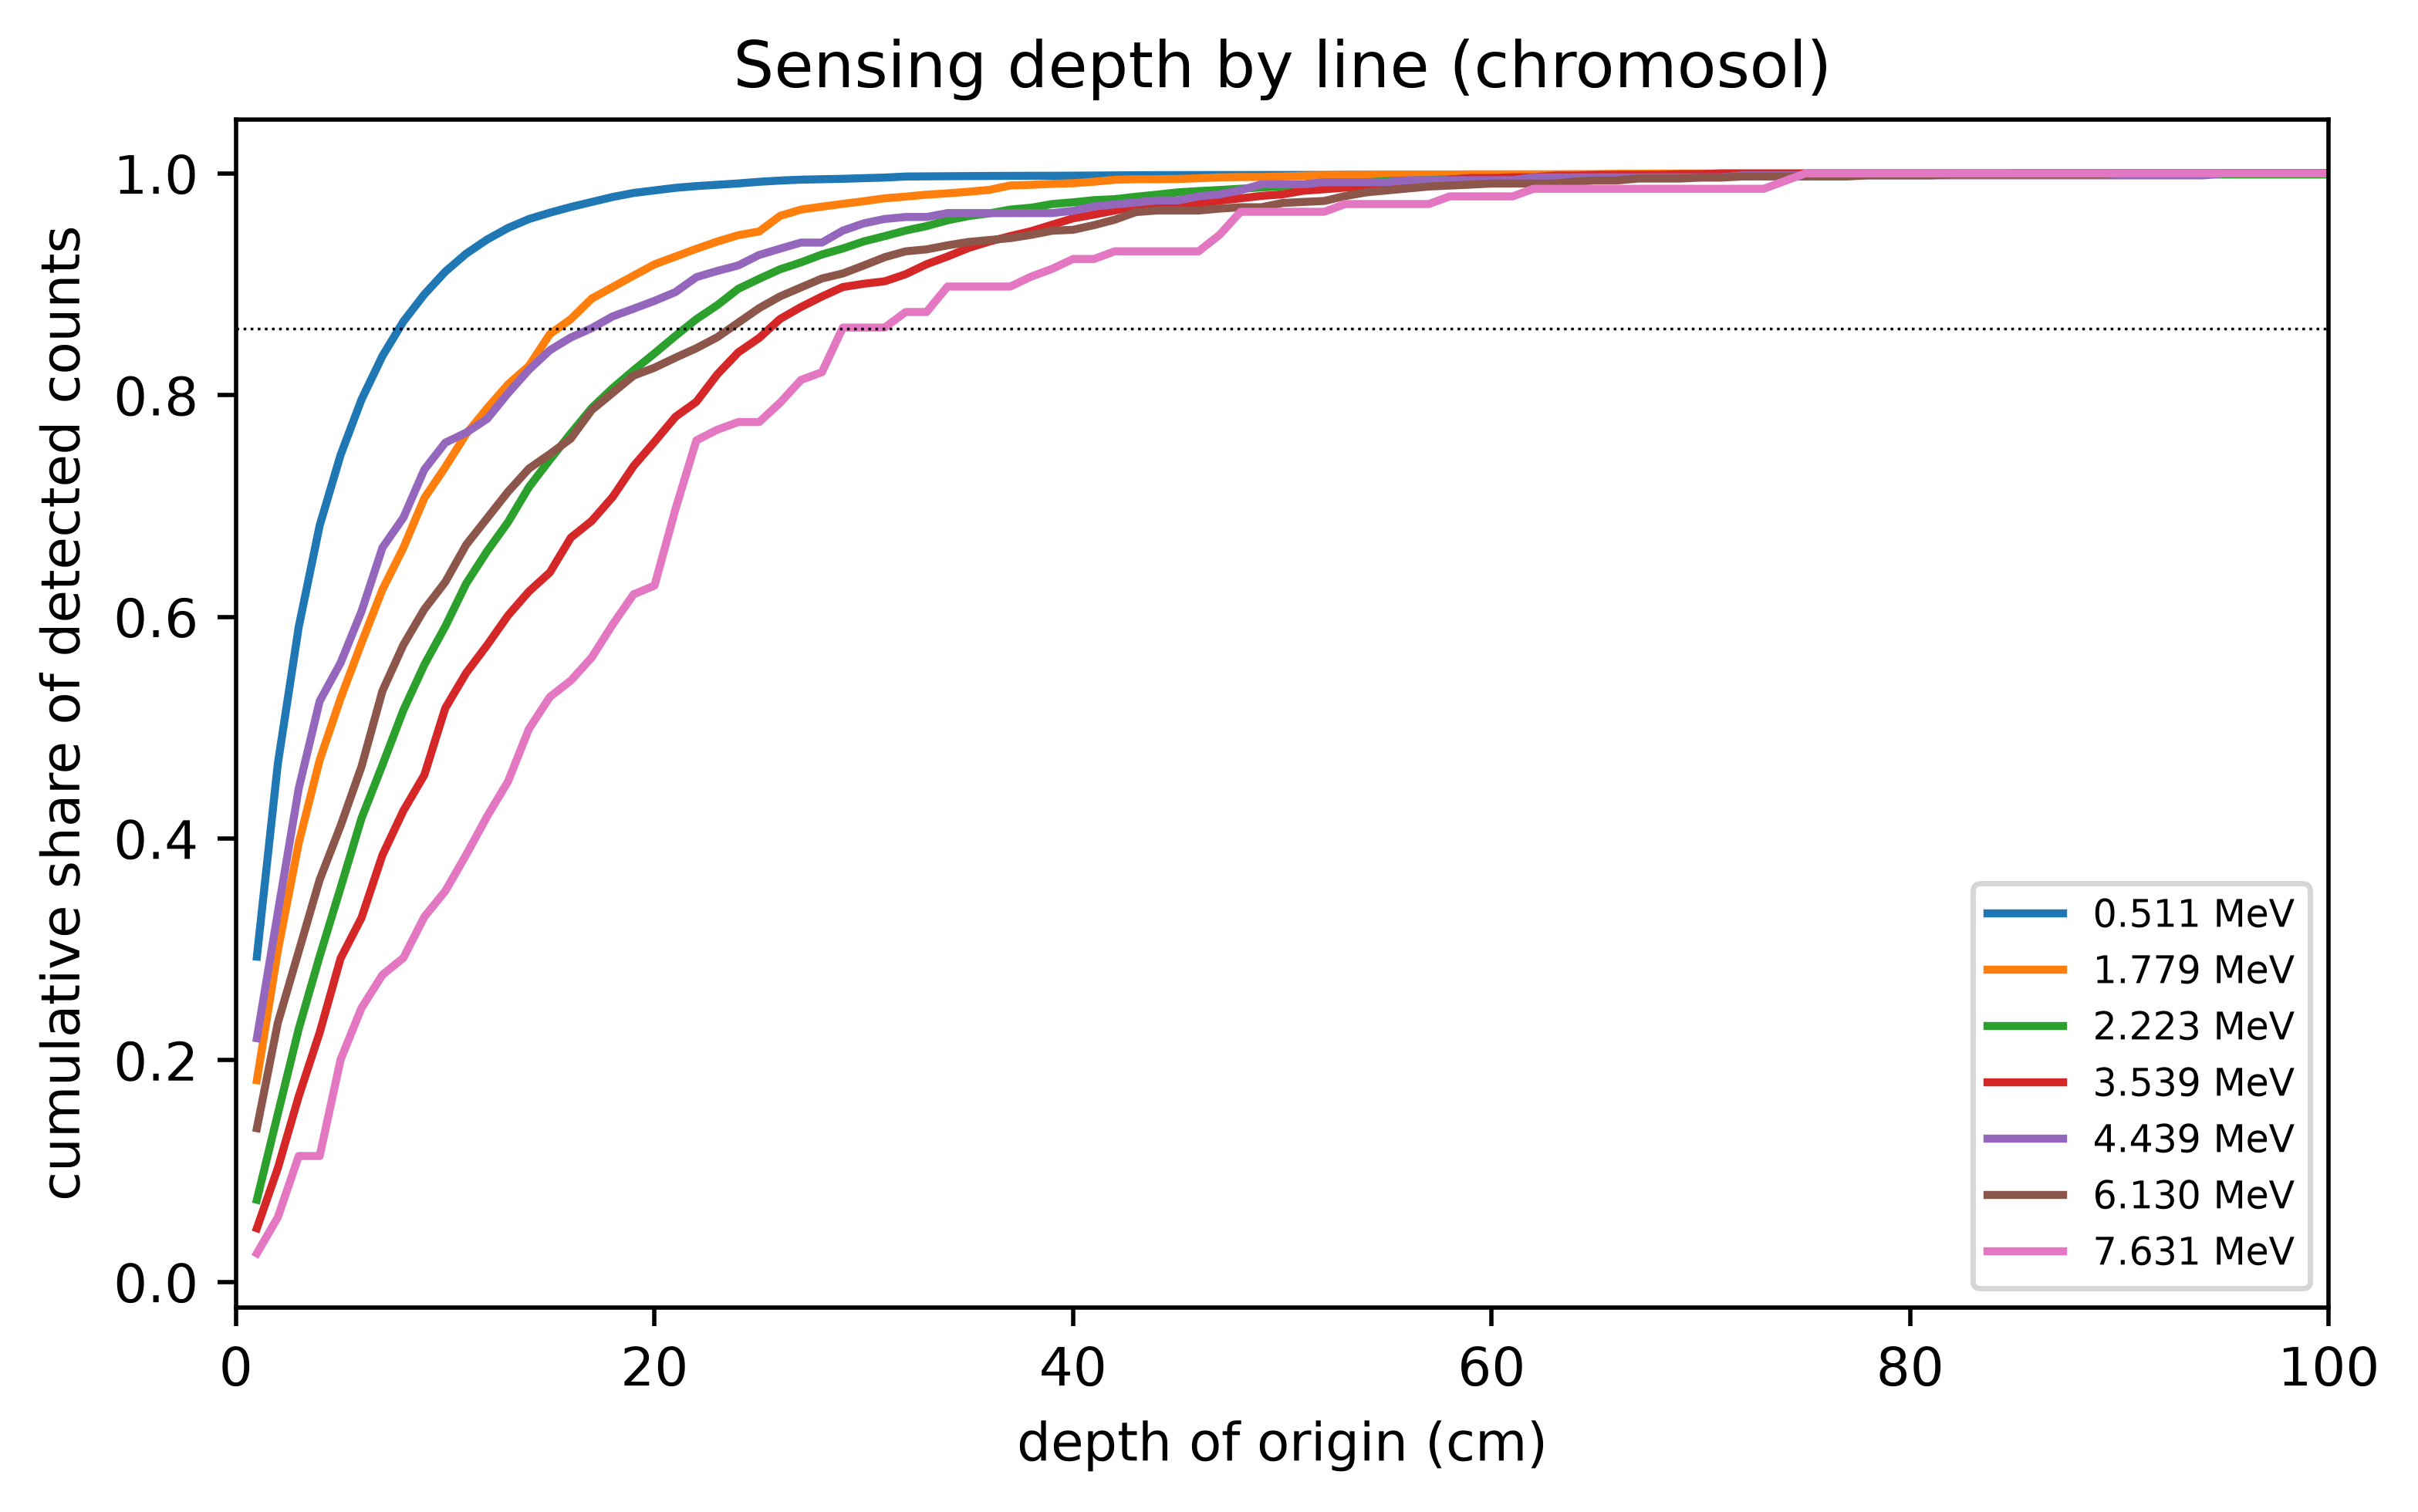

In [17]:
def depth_quantiles(row, qs=(0.5, 0.86)):
    c = np.cumsum(row) / row.sum()
    return [float(np.interp(q, c, np.arange(1, len(row) + 1))) for q in qs]


rows = []
for o in L.ORDERS:
    tdo = L.tdepth(o)
    for e_line, row in zip(L.LINE_ENERGIES, tdo):
        d50, d86 = depth_quantiles(row)
        rows.append({"Order": o, "line (MeV)": e_line, "d50 (cm)": d50, "d86 (cm)": d86})
sd = pd.DataFrame(rows)
display(sd.pivot(index="line (MeV)", columns="Order", values="d86 (cm)").round(1).rename_axis(columns="d86 (cm)"))

fig, ax = plt.subplots(figsize=(7, 4))
for e_line, row in zip(L.LINE_ENERGIES, L.tdepth(RUN)):
    if e_line in (0.511, 1.7788, 2.2232, 3.5394, 4.4389, 6.1299, 7.6311):
        ax.plot(np.arange(1, 151), np.cumsum(row) / row.sum(), label=f"{e_line:.3f} MeV")
ax.set_xlabel("depth of origin (cm)")
ax.set_ylabel("cumulative share of detected counts")
ax.set_xlim(0, 100)
ax.axhline(0.86, color="k", lw=0.5, ls=":")
ax.legend(fontsize=7)
ax.set_title(f"Sensing depth by line ({RUN})")
plt.show()

## V4: geometry convergence and variants

v3 used a 5 x 5 x 0.5 m soil block. V4 uses 40 x 40 x 1.5 m with per-area normalisation. Each variant
below changes one thing about the Chromosol central run. Rates are detected counts per day (ideal
resolution, heavy hits cleaned, capture-corrected), given as ratios to the central run with
batch-based Monte Carlo errors.

In [18]:
windows = {"0.511 ±3 keV": (508, 514), "2.223 ±3 keV": (2220, 2226), "4.40-4.48 MeV": (4400, 4480),
           "6.129 ±3 keV": (6126, 6132), "1-3 MeV": (1000, 3000), "3-8 MeV": (3000, 8000), "total": (1, 12000)}


def window_rate(spec, lo, hi):
    """Sum of a [32][12000] spectrum over [lo, hi) keV: value and batch MC sigma."""
    v = spec[:, lo:hi].sum(1)
    return v.sum(), np.sqrt(L.N_BATCH * v.var(ddof=1))


variants = ["chromosol_rep", "chromosol_depth50", "chromosol_depth100", "chromosol_depth200",
            "geo_w2p5", "geo_w40", "geo_air0p5", "geo_v3like", "geo_box10", "phys_qgsp", "phys_ts"]
central = L.cry("chromosol")
rows = []
for r in variants:
    s = L.cry(r)
    row = {"run": r, "change": L.info(r)["run"]["change"][:45]}
    for lab, (lo, hi) in windows.items():
        a, sa = window_rate(s, lo, hi)
        b, sb = window_rate(central, lo, hi)
        row[lab] = f"{a / b:.3f} ± {a / b * np.hypot(sa / a, sb / b):.3f}"
    rows.append(row)
pd.DataFrame(rows).set_index("run")

,change,0.511 ±3 keV,2.223 ±3 keV,4.40-4.48 MeV,6.129 ±3 keV,1-3 MeV,3-8 MeV,total
run,,,,,,,,
chromosol_rep,"central, independent seed (MC reproducibility",0.990 ± 0.012,1.021 ± 0.028,0.980 ± 0.093,1.037 ± 0.083,0.985 ± 0.018,0.972 ± 0.018,0.987 ± 0.005
chromosol_depth50,soil depth 50 cm,0.989 ± 0.011,0.852 ± 0.030,0.877 ± 0.061,0.882 ± 0.050,0.921 ± 0.016,0.901 ± 0.018,0.978 ± 0.006
chromosol_depth100,soil depth 100 cm,0.992 ± 0.011,1.003 ± 0.038,0.968 ± 0.065,0.870 ± 0.054,0.993 ± 0.015,0.981 ± 0.018,1.001 ± 0.005
chromosol_depth200,soil depth 200 cm,1.007 ± 0.012,1.013 ± 0.033,0.952 ± 0.098,1.018 ± 0.072,1.000 ± 0.019,0.954 ± 0.018,0.995 ± 0.005
geo_w2p5,5 x 5 m soil (v3 lateral size),0.959 ± 0.010,0.797 ± 0.032,0.847 ± 0.059,0.882 ± 0.053,0.935 ± 0.016,0.917 ± 0.019,0.965 ± 0.005
geo_w40,80 x 80 m soil,0.980 ± 0.010,1.041 ± 0.028,0.963 ± 0.063,1.017 ± 0.089,1.001 ± 0.016,0.975 ± 0.019,1.002 ± 0.005
geo_air0p5,0.5 m of air (v3),0.999 ± 0.013,0.901 ± 0.032,1.048 ± 0.115,0.959 ± 0.059,0.976 ± 0.018,0.960 ± 0.018,0.990 ± 0.005
geo_v3like,"v3-like geometry: 5 x 5 x 0.5 m soil, 0.5 m a",0.972 ± 0.011,0.628 ± 0.022,0.754 ± 0.048,0.765 ± 0.048,0.858 ± 0.015,0.819 ± 0.018,0.941 ± 0.005
geo_box10,CRY source box 10 m,0.998 ± 0.010,1.084 ± 0.034,1.133 ± 0.122,0.965 ± 0.047,1.052 ± 0.016,1.028 ± 0.021,1.050 ± 0.005


## V4: importance-sampler validation

The first four production chunks of the Chromosol central run (360 s of sky) were transported again
with brute-force uniform sampling (`val_uniform`, 20 replays) and with the importance sampler at 8
replays (`val_k8`). Both runs use the same production records, so they should agree within MC errors.
Raw spectra are used (no cleaning or correction; neither run has its own production data).

In [19]:
uni, isk = L.cry_raw("val_uniform"), L.cry_raw("val_k8")
bands = {"0.3-1 MeV": (300, 1000), "1-2 MeV": (1000, 2000), "2-3 MeV": (2000, 3000), "3-5 MeV": (3000, 5000),
         "5-8 MeV": (5000, 8000), "2.223 ±3 keV": (2220, 2226), "0.511 ±3 keV": (508, 514), "total": (1, 12000)}
rows = []
for lab, (lo, hi) in bands.items():
    a, sa = window_rate(isk, lo, hi)
    b, sb = window_rate(uni, lo, hi)
    r = a / b
    sr = r * np.hypot(sa / a, sb / b)
    rows.append({"band": lab, "IS (k=8) per day": a * DAY, "uniform per day": b * DAY,
                 "IS / uniform": f"{r:.3f} ± {sr:.3f}", "pull": (r - 1) / sr})
pd.DataFrame(rows).set_index("band").round(2)

,IS (k=8) per day,uniform per day,IS / uniform,pull
band,,,,
0.3-1 MeV,94679.03,94427.93,1.003 ± 0.027,0.10
1-2 MeV,14649.83,13806.83,1.061 ± 0.057,1.07
2-3 MeV,6308.77,6974.33,0.905 ± 0.085,-1.12
3-5 MeV,6390.48,5541.76,1.153 ± 0.105,1.46
5-8 MeV,3976.66,4938.58,0.805 ± 0.068,-2.85
2.223 ±3 keV,588.30,716.28,0.821 ± 0.207,-0.86
0.511 ±3 keV,26141.18,24207.64,1.080 ± 0.043,1.84
total,375636.85,368867.58,1.018 ± 0.013,1.42


## V4: CRY source size in the analog runs

The analog runs throw CRY showers over a 5 m box (12 h of sky) and a 10 m box (3 h). If the 5 m box
were too small, particles arriving from distant shower cores would be missing and the tag-plane rates
would rise with the 10 m box. Errors are Poisson on the crossing counts; one shower often gives
several crossings, so they are somewhat too small.

In [20]:
rates = {}
for aid in ("analog_box5", "analog_box10"):
    a = L.analog(aid)
    names = pd.Series([PDG_NAMES.get(p, "ion" if p > 1000000000 else str(p)) for p in a["tags"]["pdg"]])
    n = names.value_counts()
    rates[aid] = pd.DataFrame({"per s": n / a["exposure_s"], "err": np.sqrt(n) / a["exposure_s"]})
    rates[aid].loc["detector pulses"] = [len(a["pulses"]) / a["exposure_s"], np.sqrt(len(a["pulses"])) / a["exposure_s"]]
cmp = rates["analog_box5"].join(rates["analog_box10"], lsuffix=" (box 5 m)", rsuffix=" (box 10 m)")
cmp["10 m / 5 m"] = cmp["per s (box 10 m)"] / cmp["per s (box 5 m)"]
cmp["± (Poisson)"] = cmp["10 m / 5 m"] * np.hypot(cmp["err (box 10 m)"] / cmp["per s (box 10 m)"],
                                               cmp["err (box 5 m)"] / cmp["per s (box 5 m)"])
cmp.sort_values("per s (box 5 m)", ascending=False).round(4)

,per s (box 5 m),err (box 5 m),per s (box 10 m),err (box 10 m),10 m / 5 m,± (Poisson)
gamma,95.6870,0.0471,100.0644,0.0963,1.0457,0.0011
mu+,21.5475,0.0223,21.6393,0.0448,1.0043,0.0023
mu-,20.0488,0.0215,20.0409,0.0431,0.9996,0.0024
detector pulses,18.8527,0.0209,20.1488,0.0432,1.0687,0.0026
neutron,10.2812,0.0154,10.9875,0.0319,1.0687,0.0035
e-,10.0308,0.0152,10.4297,0.0311,1.0398,0.0035
e+,4.0904,0.0097,4.1316,0.0196,1.0101,0.0054
nu_e,1.3049,0.0055,1.8495,0.0131,1.4173,0.0117
anti_nu_e,1.0181,0.0049,1.4612,0.0116,1.4352,0.0133
anti_nu_mu,0.7256,0.0041,1.0648,0.0099,1.4674,0.0160
